# Four ways to look at a dataset

A short tour of visualisation techniques, using the Crimean mortality table.
`nightingale_crimean_mortality_clean.csv` holds 24 monthly observations, April 1854 – March
1856: average British army strength, and deaths split into **disease**, **wounds**, and
**other**.

Each section covers one chart type: **what question it answers**, the code, and **what it shows
here**. The point is the technique, so the charts stay deliberately plain.

|  | Chart | Good for |
|---|-------|----------|
| 2 | Line | trend and turning points |
| 3 | Small multiples | comparing several series, and the axis-scaling trade-off |
| 4 | Stacked bar | composition and magnitude at once |
| 5 | Ranked bar | which items are extreme |

## 1. Load the data

The clean file stores only what was *measured*. Rates are computed here, in three lines, because
a **death count can't be compared across months when the army changes size** — this force grew
from 8,571 to 46,140 men. Dividing by strength converts counts into risk.

The convention is annualised deaths per 1,000 troops: `deaths / army × 12 × 1000`. The 12 turns
a monthly figure into a yearly one; the 1,000 avoids a column of tiny decimals.

In [2]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

CAUSES = ["disease", "wounds", "other"]
COLORS = {"disease": "#8c2d19", "wounds": "#c9a227", "other": "#4a6670"}

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left"})

df = pd.read_csv("nightingale_crimean_mortality.csv", parse_dates=["date"])

# --- the only derived columns we need ---
df["deaths_total"] = df[[f"deaths_{c}" for c in CAUSES]].sum(axis=1)
for c in CAUSES:
    df[f"rate_{c}"] = df[f"deaths_{c}"] * 12 * 1000 / df["army"]

df["rate_all_cause"] = df["deaths_total"] * 12 * 1000 / df["army"]

df.head(5)

,date,month,year,period,army,deaths_disease,deaths_wounds,deaths_other,deaths_total,rate_disease,rate_wounds,rate_other,rate_all_cause
0,1854-04-01,Apr,1854,Before,8571,1,0,5,6,1.400070,0.000000,7.000350,8.400420
1,1854-05-01,May,1854,Before,23333,12,0,9,21,6.171517,0.000000,4.628638,10.800154
2,1854-06-01,Jun,1854,Before,28333,11,0,6,17,4.658878,0.000000,2.541206,7.200085
3,1854-07-01,Jul,1854,Before,28722,359,0,23,382,149.989555,0.000000,9.609359,159.598914
4,1854-08-01,Aug,1854,Before,30246,828,1,30,859,328.506249,0.396747,11.902400,340.805396


## 2. Line chart: what shape is the trend?

The default choice for anything measured over time. Lines imply continuity between points, which
is appropriate here: consecutive months are genuinely connected.

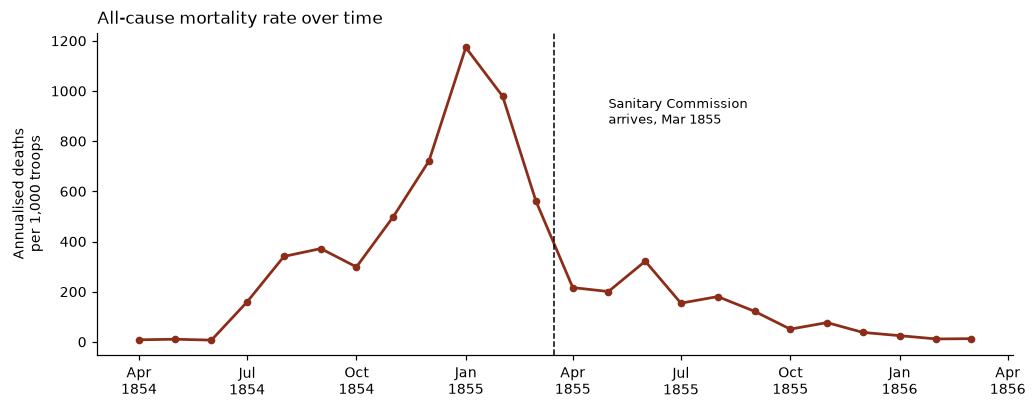

In [4]:
fig, ax = plt.subplots(figsize=(9.5, 3.8))

ax.plot(df["date"], df["rate_all_cause"], marker="o", ms=4, lw=1.8, color="#8c2d19")

# The Sanitary Commission reached the army hospitals in March 1855.
ax.axvline(pd.Timestamp("1855-03-16"), color="black", ls="--", lw=1)
ax.annotate("Sanitary Commission\narrives, Mar 1855", xy=(pd.Timestamp("1855-03-16"), 950),
            xytext=(pd.Timestamp("1855-05-01"), 870), fontsize=8.5)

ax.set_title("All-cause mortality rate over time")
ax.set_ylabel("Annualised deaths\nper 1,000 troops")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
plt.tight_layout()
plt.show()

A single sharp peak in January 1855, then a fall that never reverses. The eye picks out the shape
instantly — one rise, one peak, one decline — which is exactly what a line chart is for.

## 3. Small multiples: how do several series compare?

Rather than crowding three causes onto one pair of axes, give each its own panel. The technique
scales well: ten series would be unreadable overlaid but fine as ten small panels.

**The choice that matters is the y-axis.** Below, the same data twice:

- **Top row, shared axis** (`sharey=True`) — panels are directly comparable, so relative
  magnitude is honest, but small series get flattened into nothing.
- **Bottom row, free axis** — each panel's shape becomes visible, but the panels are no longer
  comparable and a casual reader may think the three are similar in size.

Neither is right in general. Shared axes answer "which is bigger?"; free axes answer "what shape
is each one?"

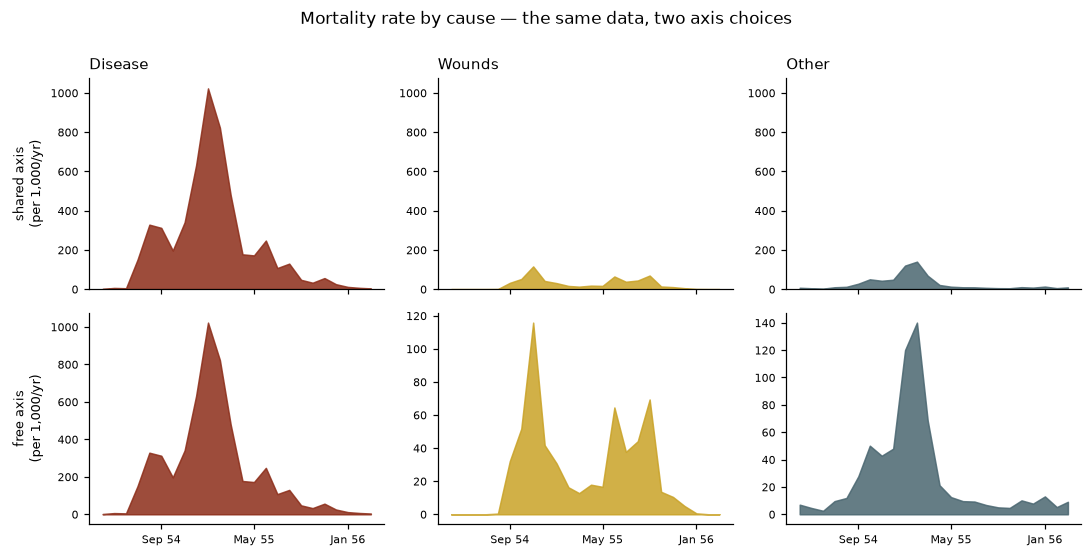

Rate range by cause (per 1,000/yr):
  disease     1.4 to  1022.8
  wounds      0.0 to   115.8
  other       2.5 to   140.1


In [5]:
fig, axes = plt.subplots(2, 3, figsize=(10, 5), sharex=True)

for row, share_y in enumerate([True, False]):
    for col, cause in enumerate(CAUSES):
        ax = axes[row, col]
        ax.fill_between(df["date"], df[f"rate_{cause}"], color=COLORS[cause], alpha=0.85)
        if share_y:
            ax.set_ylim(0, df["rate_disease"].max() * 1.05)   # common scale across the row
        if row == 0:
            ax.set_title(cause.capitalize(), fontsize=10)
        ax.tick_params(labelsize=7.5)
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=8))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))

axes[0, 0].set_ylabel("shared axis\n(per 1,000/yr)", fontsize=8.5)
axes[1, 0].set_ylabel("free axis\n(per 1,000/yr)", fontsize=8.5)
fig.suptitle("Mortality rate by cause — the same data, two axis choices", y=1.0, fontsize=11)
plt.tight_layout()
plt.show()

print("Rate range by cause (per 1,000/yr):")
for c in CAUSES:
    print(f"  {c:<8} {df[f'rate_{c}'].min():>6.1f} to {df[f'rate_{c}'].max():>7.1f}")

The top row carries the real message: disease dwarfs the other two so completely that wounds and
other causes are nearly invisible beside it. The bottom row adds something the top row hides —
wounds mortality has its own pattern, with bumps that don't line up with the disease peak at all.

You need both readings. Only the shared-axis row tells you the wounds pattern is small.

## 4. Stacked bar

Stacking shows **composition and total simultaneously**: the full bar height is the month's
deaths, and the segments show what they were made of.

The trade-off: only the bottom segment sits on a flat baseline, so it is the only one whose
individual shape is easy to read. Put the series you most want understood at the bottom, and
don't stack more than a few categories.

Here we plot **counts**, not rates — a stacked bar of deaths answers "how many men died", which
is a fair question in its own right, as long as you don't read it as risk.

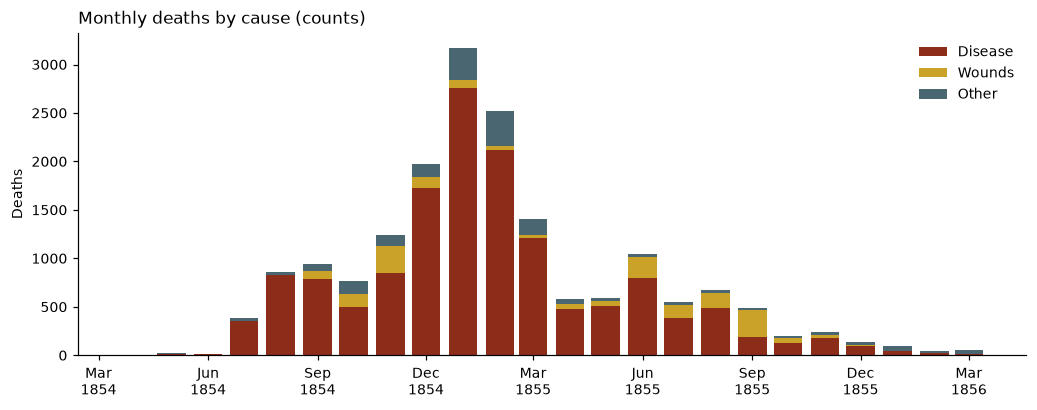

Disease  14,476  (80.5%)
Wounds    1,758  ( 9.8%)
Other     1,748  ( 9.7%)
Total    17,982


In [6]:
fig, ax = plt.subplots(figsize=(9.5, 3.8))

bottom = np.zeros(len(df))
for cause in CAUSES:                       # disease first, so it sits on the baseline
    ax.bar(df["date"], df[f"deaths_{cause}"], width=24, bottom=bottom,
           color=COLORS[cause], label=cause.capitalize())
    bottom += df[f"deaths_{cause}"].to_numpy()

ax.set_title("Monthly deaths by cause (counts)")
ax.set_ylabel("Deaths")
ax.legend(frameon=False)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
plt.tight_layout()
plt.show()

totals = {c: df[f"deaths_{c}"].sum() for c in CAUSES}
grand = sum(totals.values())
for c, n in totals.items():
    print(f"{c.capitalize():<8} {n:>6,}  ({n/grand:>5.1%})")
print(f"{'Total':<8} {grand:>6,}")

Dark red almost everywhere: **disease caused 80.5% of all deaths**, roughly eight for every
battle death. For a campaign remembered as a war, that is the finding.

## 5. Ranked bar: which items are extreme?

When the question is "which were the worst?" rather than "how did it change?", sort by value and
drop the time axis. Horizontal bars suit this: labels read left-to-right without rotation, and
sorted length is one of the easiest visual comparisons there is.

`nlargest` does the sorting; note that this discards chronology entirely, which is the point.

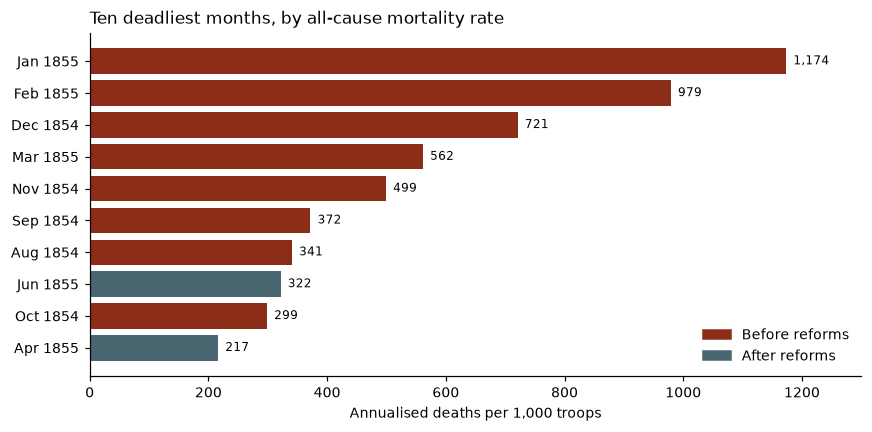

Of the 10 worst months, 8 fall before the reforms.


In [7]:
top = df.nlargest(10, "rate_all_cause").iloc[::-1]     # reversed so the worst lands on top
labels = top["month"] + " " + top["year"].astype(str)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(labels, top["rate_all_cause"],
               color=[COLORS["disease"] if p == "Before" else "#4a6670" for p in top["period"]])

for bar, value in zip(bars, top["rate_all_cause"]):
    ax.text(value + 12, bar.get_y() + bar.get_height() / 2, f"{value:,.0f}",
            va="center", fontsize=8)

ax.set_title("Ten deadliest months, by all-cause mortality rate")
ax.set_xlabel("Annualised deaths per 1,000 troops")
ax.set_xlim(0, 1300)
handles = [plt.Rectangle((0, 0), 1, 1, color=COLORS["disease"]),
           plt.Rectangle((0, 0), 1, 1, color="#4a6670")]
ax.legend(handles, ["Before reforms", "After reforms"], frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

print(f"Of the 10 worst months, {(top['period'] == 'Before').sum()} fall before the reforms.")